# 1장 추론, 베이즈 정리, 변분 자유 에너지 (실습)

이 노트북이 답하는 질문은 하나다. **계산할 수 없는 분모 p(y) 없이, 자유 에너지를 줄이는 것만으로 베이즈 사후 분포를 찾을 수 있는가?**

순서는 이렇다. 가우스 밀도와 베이즈 정리를 손에 익히고, 분모를 직접 적분하는 기준선을 세운 뒤, 자유 에너지 경사 하강이 같은 답에 닿는지 잰다. 자유 에너지의 세 가지 분해가 정말 같은 값인지 숫자로 확인하고, 정밀도가 믿음을 어디로 끄는지 본다. 마지막으로 라플라스 근사가 무너지는 경우를 일부러 만든다.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})

def gauss(x, m, s2):
    """평균 m, 분산 s2 인 가우스 밀도."""
    return np.exp(-(x - m)**2 / (2 * s2)) / np.sqrt(2 * np.pi * s2)

print("준비 완료, numpy", np.__version__)

준비 완료, numpy 2.5.4


## 1. 가우스 밀도

평균 μ 와 표준편차 σ 두 수로 분포 전체가 정해진다. 연습할수록 평균은 멀어지고 분포는 좁아지는 모습을 그린다.

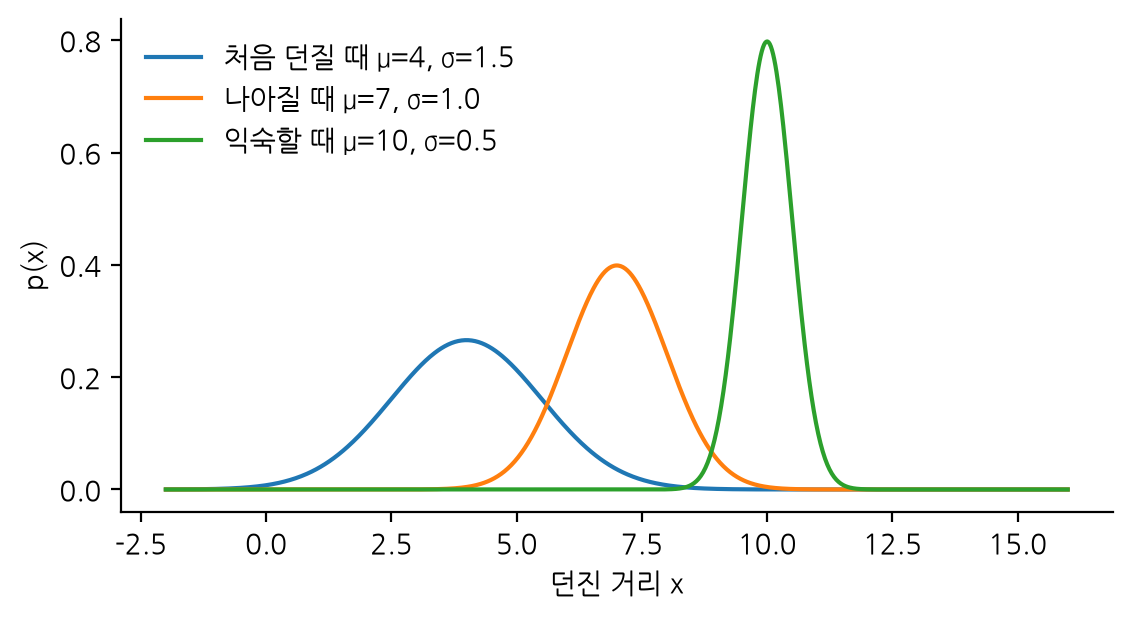

In [2]:
x = np.linspace(-2, 16, 800)
for mu, s, label in [(4, 1.5, "처음 던질 때"), (7, 1.0, "나아질 때"), (10, 0.5, "익숙할 때")]:
    plt.plot(x, gauss(x, mu, s**2), label=f"{label} μ={mu}, σ={s}")
plt.xlabel("던진 거리 x")
plt.ylabel("p(x)")
plt.legend(frameon=False)
plt.show()

## 2. 베이즈 정리 — 주사위

주사위를 한 개(40%) 또는 두 개(60%) 던지고 합만 알려 준다. 합을 보고 두 개를 던졌을 확률을 5000번 흉내로 센다.

In [3]:
rng = np.random.default_rng(1234567)
N = 5000
N1 = int(N * 0.4)          # 주사위 1개를 던진 횟수
N2 = N - N1                # 주사위 2개를 던진 횟수

one = np.bincount(rng.integers(1, 7, N1), minlength=13)
two = np.bincount(rng.integers(1, 7, N2) + rng.integers(1, 7, N2), minlength=13)

# 관측된 합마다 p(2개 | 합) 을 센다
p2 = {obs: two[obs] / (one[obs] + two[obs]) for obs in range(1, 13)}
print(" ".join(f"{o}:{100 * p:.0f}%" for o, p in p2.items()))
print(f"손 계산 p(2개 | 4) = {(3/36 * 0.6) / (1/6 * 0.4 + 3/36 * 0.6):.3f}")

1:0% 2:19% 3:31% 4:41% 5:52% 6:55% 7:100% 8:100% 9:100% 10:100% 11:100% 12:100%
손 계산 p(2개 | 4) = 0.429


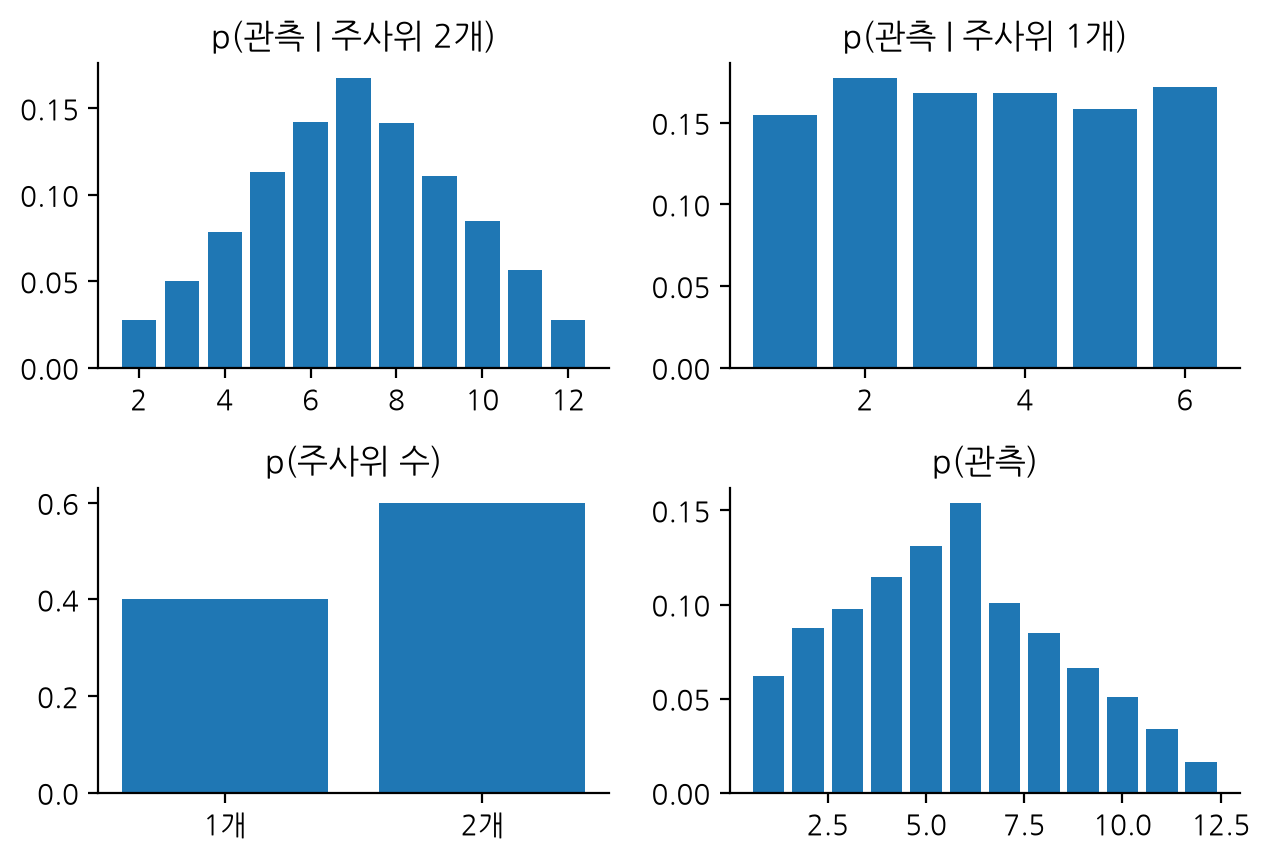

In [4]:
k = np.arange(13)
fig, axs = plt.subplots(2, 2, figsize=(6.4, 4.4))
axs[0, 0].bar(k[2:], two[2:] / N2);  axs[0, 0].set_title("p(관측 | 주사위 2개)")
axs[0, 1].bar(k[1:7], one[1:7] / N1); axs[0, 1].set_title("p(관측 | 주사위 1개)")
axs[1, 0].bar(["1개", "2개"], [N1 / N, N2 / N]); axs[1, 0].set_title("p(주사위 수)")
axs[1, 1].bar(k[1:], (one[1:] + two[1:]) / N); axs[1, 1].set_title("p(관측)")
fig.tight_layout()
plt.show()

## 3. 기준선 — 분모를 직접 적분한다

사전 믿음 x ~ N(3, 1), 감각 사상 g(x) = 2x, 감각 잡음 분산 1, 관측 y = 8 인 문제를 쓴다. 1차원이라 격자 위에서 분모 p(y) 를 그대로 적분할 수 있다. 이것이 뒤의 방법들이 맞춰야 할 정답이다.

In [5]:
v, s2_w = 3.0, 1.0      # 사전 믿음: x 의 평균과 분산
s2_z = 1.0              # 감각 잡음의 분산
y = 8.0                 # 들어온 관측
g  = lambda x: 2 * x    # 감각 사상 g(x)
dg = lambda x: 2.0      # g 의 도함수

xs = np.linspace(-5, 12, 34001)
dx = xs[1] - xs[0]
joint = gauss(y, g(xs), s2_z) * gauss(xs, v, s2_w)   # p(y | x) p(x)
evidence = joint.sum() * dx                          # 분모 p(y)
post = joint / evidence                              # 정확한 사후 p(x | y)
post_mean = (xs * post).sum() * dx
post_var = ((xs - post_mean)**2 * post).sum() * dx
print(f"p(y) = {evidence:.5f},  놀람 -ln p(y) = {-np.log(evidence):.4f}")
print(f"정확한 사후: 평균 {post_mean:.4f}, 분산 {post_var:.4f}")

p(y) = 0.11959,  놀람 -ln p(y) = 2.1237
정확한 사후: 평균 3.8000, 분산 0.2000


## 4. 방법 — 자유 에너지 경사 하강

라플라스 근사 아래의 자유 에너지는 정밀도로 가중한 예측 오차 두 개의 제곱합이다. 분모 없이 이 값의 기울기만 따라 내려간다.

In [6]:
def free_energy(mu):
    eps_y = y - g(mu)   # 감각 예측 오차
    eps_x = mu - v      # 사전 예측 오차
    return eps_y**2 / (2 * s2_z) + eps_x**2 / (2 * s2_w)

mu, lr = v, 0.05
trace = [mu]
for step in range(60):
    dF = -(y - g(mu)) * dg(mu) / s2_z + (mu - v) / s2_w
    mu -= lr * dF
    trace.append(mu)
    if step % 15 == 0:
        print(f"step {step:2d}  mu={mu:.3f}  F={free_energy(mu):.3f}")
print(f"경사 하강 결과 mu={mu:.4f}, 기준선 사후 평균={post_mean:.4f}")

step  0  mu=3.200  F=1.300
step 15  mu=3.792  F=0.400
step 30  mu=3.800  F=0.400
step 45  mu=3.800  F=0.400
경사 하강 결과 mu=3.8000, 기준선 사후 평균=3.8000


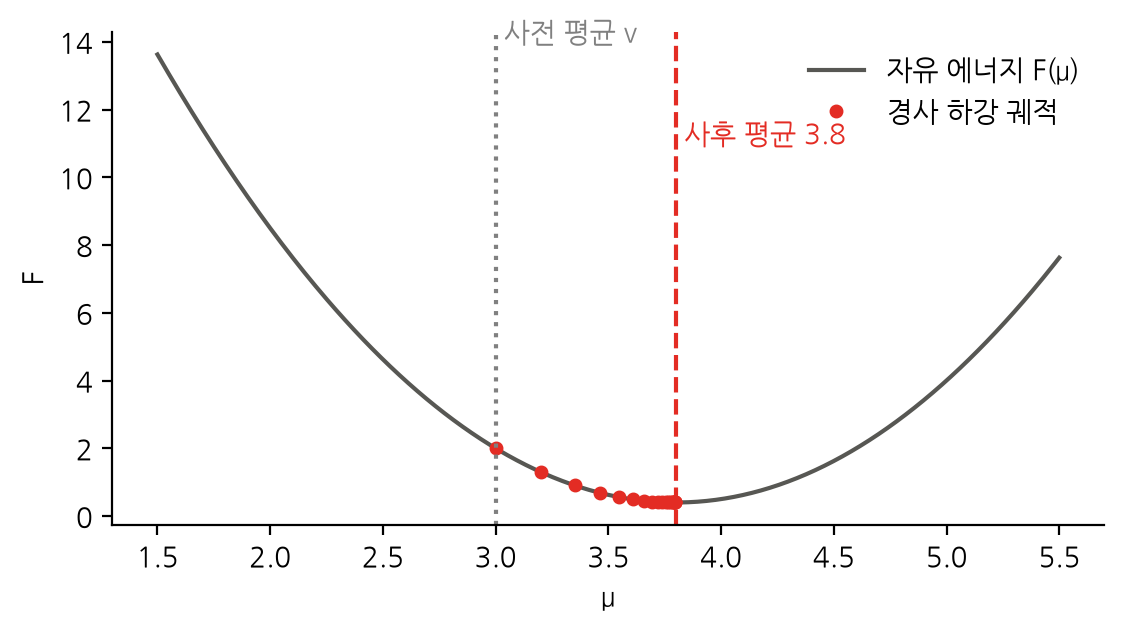

In [7]:
m = np.linspace(1.5, 5.5, 400)
tr = np.array(trace[:21])
plt.plot(m, free_energy(m), color="#575753", label="자유 에너지 F(μ)")
plt.plot(tr, free_energy(tr), "o", color="#E32C24", ms=4, label="경사 하강 궤적")
plt.axvline(v, ls=":", color="gray")
plt.axvline(post_mean, ls="--", color="#E32C24")
plt.text(v, 14, " 사전 평균 v", color="gray")
plt.text(post_mean, 11, f" 사후 평균 {post_mean:.1f}", color="#E32C24")
plt.xlabel("μ"); plt.ylabel("F")
plt.legend(frameon=False, loc="upper right")
plt.show()

## 5. 측정 — 자유 에너지의 세 얼굴이 같은 값인가

인식 밀도 q = N(μ, s²) 를 두 개 골라 격자 위에서 자유 에너지를 세 가지로 계산한다. 하나는 정확한 사후와 같은 q, 다른 하나는 사전 믿음을 그대로 쓴 q 다. 세 값이 일치해야 하고, 정확한 사후일 때만 F 가 놀람과 같아져야 한다.

In [8]:
log_joint = np.log(gauss(y, g(xs), s2_z)) + np.log(gauss(xs, v, s2_w))
surprise = -np.log(evidence)

def faces(m_q, s2_q):
    q = gauss(xs, m_q, s2_q)
    E = lambda f: (q * f).sum() * dx                      # q 로 평균
    H = -E(np.log(q))                                     # 엔트로피
    energy = E(-log_joint)
    complexity = E(np.log(q) - np.log(gauss(xs, v, s2_w)))
    accuracy = E(np.log(gauss(y, g(xs), s2_z)))
    kl_post = E(np.log(q) - np.log(post))
    return energy - H, complexity - accuracy, kl_post + surprise

for name, (m_q, s2_q) in {"q = 정확한 사후": (post_mean, post_var),
                          "q = 사전 믿음": (v, s2_w)}.items():
    a, b, c = faces(m_q, s2_q)
    print(f"{name:12s} 에너지-엔트로피 {a:.4f} | 복잡도-정확도 {b:.4f} | KL+놀람 {c:.4f}")
print(f"놀람 -ln p(y) = {surprise:.4f}")

q = 정확한 사후   에너지-엔트로피 2.1237 | 복잡도-정확도 2.1237 | KL+놀람 2.1237
q = 사전 믿음    에너지-엔트로피 4.9189 | 복잡도-정확도 4.9189 | KL+놀람 4.9189
놀람 -ln p(y) = 2.1237


## 6. 비교 — 정밀도가 믿음을 어디로 끄는가

감각 잡음의 분산을 바꿔 가며 자유 에너지 최소점을 구한다. 관측만 믿으면 답은 y/2 = 4, 사전만 믿으면 3 이다.

In [9]:
def settle(s2_z_, steps=4000, lr=0.002):
    m = v
    for _ in range(steps):
        m -= lr * (-(y - g(m)) * dg(m) / s2_z_ + (m - v) / s2_w)
    return m

print("감각 분산  감각 정밀도  μ*      (관측 쪽 4, 사전 쪽 3)")
for s2 in [0.1, 1.0, 4.0, 10.0, 100.0]:
    print(f"{s2:8.1f}  {1 / s2:10.2f}  {settle(s2):.3f}")

감각 분산  감각 정밀도  μ*      (관측 쪽 4, 사전 쪽 3)
     0.1       10.00  3.976
     1.0        1.00  3.800
     4.0        0.25  3.500
    10.0        0.10  3.286
   100.0        0.01  3.038


## 7. 실패 조건 — 사후 분포에 봉우리가 둘일 때

감각 사상을 g(x) = x² 로 바꾸고 y = 4 를 관측하면 x = 2 와 x = −2 가 둘 다 관측을 잘 설명한다. 정확한 사후에는 봉우리가 둘 생긴다. 가우스 하나로 근사하는 라플라스 근사는 출발점에 따라 한쪽 봉우리만 잡는다.

In [10]:
g2, dg2 = lambda x: x**2, lambda x: 2 * x
v2, s2_w2, s2_z2, y2 = 0.5, 4.0, 0.5, 4.0
joint2 = gauss(y2, g2(xs), s2_z2) * gauss(xs, v2, s2_w2)
post2 = joint2 / (joint2.sum() * dx)

def settle2(m, steps=3000, lr=0.005):
    for _ in range(steps):
        m -= lr * (-(y2 - g2(m)) * dg2(m) / s2_z2 + (m - v2) / s2_w2)
    return m

for start in [0.5, -0.5]:
    m = settle2(start)
    curv = (dg2(m)**2 - (y2 - g2(m)) * 2) / s2_z2 + 1 / s2_w2   # F 의 곡률
    print(f"출발 {start:+.1f} → μ* = {m:+.3f}, 라플라스 분산 {1 / curv:.3f}")
print(f"정확한 사후에서 x < 0 쪽 확률 = {(post2[xs < 0]).sum() * dx:.3f}")

출발 +0.5 → μ* = +1.988, 라플라스 분산 0.032
출발 -0.5 → μ* = -1.980, 라플라스 분산 0.032


정확한 사후에서 x < 0 쪽 확률 = 0.380


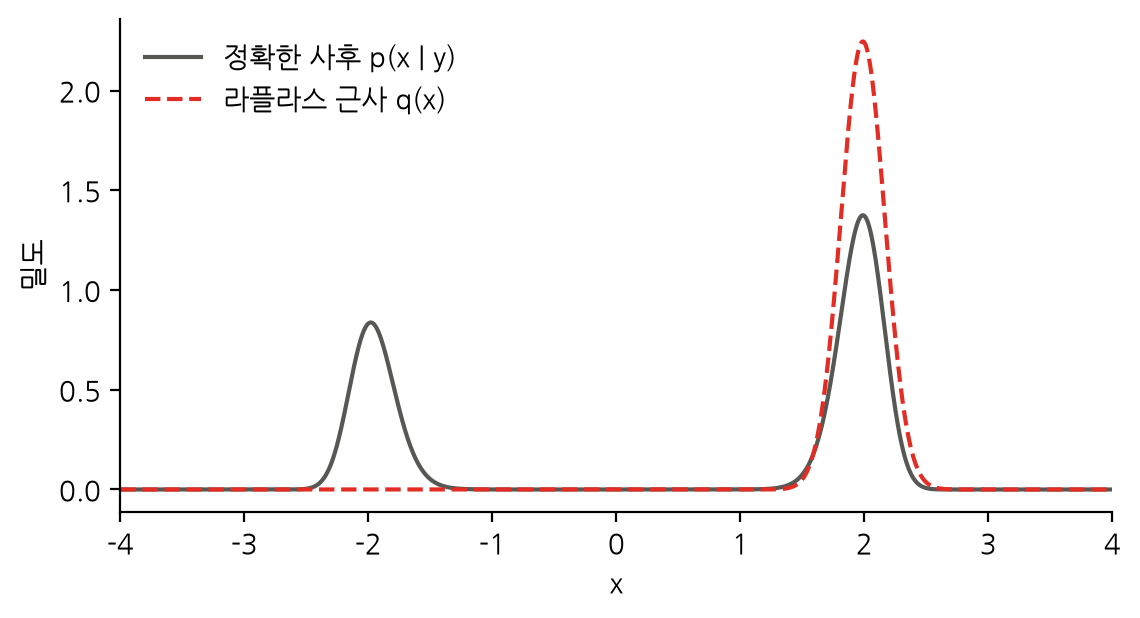

In [11]:
m_r = settle2(0.5)
s2_r = 1 / ((dg2(m_r)**2 - (y2 - g2(m_r)) * 2) / s2_z2 + 1 / s2_w2)
plt.plot(xs, post2, color="#575753", label="정확한 사후 p(x | y)")
plt.plot(xs, gauss(xs, m_r, s2_r), "--", color="#E32C24", label="라플라스 근사 q(x)")
plt.xlim(-4, 4)
plt.xlabel("x"); plt.ylabel("밀도")
plt.legend(frameon=False)
plt.show()

## 결론

- 분모 p(y) 를 적분한 기준선의 사후 평균 3.8 에, 자유 에너지 경사 하강이 분모 없이 그대로 닿는다.
- 자유 에너지의 세 가지 분해는 같은 값을 낸다. 인식 밀도가 정확한 사후일 때 F 는 놀람과 같아지고, 그 밖에는 언제나 놀람보다 크다.
- 감각 정밀도가 높을수록 믿음은 관측 쪽으로, 낮을수록 사전 쪽으로 간다.
- 사후 분포의 봉우리가 여럿이면 라플라스 근사는 출발점 근처의 봉우리 하나만 잡고 나머지 확률을 놓친다. 가우스 가정이 공짜가 아니라는 뜻이다.